# Workshop 2: reading the Silver layer (Team 5, Extreme Weather Monitoring, Texas)

The Silver DAG writes one Parquet file per topic and processing run in `datalake_silver/`, named
`topic_YYYYMMDD_HHMMSS.parquet`. This notebook shows how to read those files with Pandas, how to trace
a row back to its Bronze file, and what the data look like after cleaning.

Topics: `station_observations` (F4), `weather_alerts` (F3), `daily_summaries` (F2), `storm_events` (F1).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

SILVER = Path("../datalake_silver")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

files = sorted(SILVER.glob("*.parquet"))
pd.DataFrame({"file": [f.name for f in files],
              "rows": [pq.read_metadata(f).num_rows for f in files],
              "size_kb": [round(f.stat().st_size / 1024, 1) for f in files]})

,file,rows,size_kb
0,daily_summaries_20261117_010918.parquet,71,15.2
1,daily_summaries_20261117_011045.parquet,1095,63.9
2,station_observations_20261117_010918.parquet,85,19.6
3,station_observations_20261117_010959.parquet,3,14.3
4,storm_events_20261117_010918.parquet,5641,724.2
5,weather_alerts_20261117_010918.parquet,169,116.6


## 1. Read one Silver file

We open the latest `station_observations` file. Parquet stores the data types, so timestamps arrive as
UTC datetimes and the station code as a category, with no parsing step.

In [2]:
latest = sorted(SILVER.glob("station_observations_*.parquet"))[-1]
obs_one = pd.read_parquet(latest)
print(latest.name, obs_one.shape)
obs_one.dtypes

station_observations_20261117_010959.parquet (3, 22)


icao                                 category
timestamp_utc             datetime64[us, UTC]
latitude                              float64
longitude                             float64
temperature_c                         float64
dewpoint_c                            float64
relative_humidity_pct                 float64
wind_speed_ms                         float64
wind_gust_ms                          float64
wind_direction_deg                    float64
pressure_hpa                          float64
sea_level_pressure_hpa                float64
precip_1h_mm                          float64
precip_3h_mm                          float64
temperature_qc                       category
text_description                       string
out_of_range                           string
temperature_outlier                      bool
record_hash                            string
bronze_file                            string
ingested_at               datetime64[us, UTC]
processed_at              datetime

In [3]:
obs_one.head()

,icao,timestamp_utc,latitude,longitude,temperature_c,dewpoint_c,relative_humidity_pct,wind_speed_ms,wind_gust_ms,wind_direction_deg,pressure_hpa,sea_level_pressure_hpa,precip_1h_mm,precip_3h_mm,temperature_qc,text_description,out_of_range,temperature_outlier,record_hash,bronze_file,ingested_at,processed_at
0,KDFW,2026-11-17 00:45:00+00:00,32.90,-97.03,13.0,0.0,40.865675,1.54,NaN,20.0,1028.1076,NaN,NaN,NaN,V,clear,,False,de42210a1b544b5d113c39bd0a2b9676e16d88c3,nws_observations_20261117_010000.json,2026-11-17 01:00:09+00:00,2026-11-17 01:10:01.180981+00:00
1,KAUS,2026-11-17 00:45:00+00:00,30.19,-97.67,11.0,8.0,81.750052,3.60,NaN,360.0,1027.7690,NaN,NaN,NaN,V,mostly clear,,False,0240a5b38957af7c5192bc4321e179b2e3186e93,nws_observations_20261117_010000.json,2026-11-17 01:00:09+00:00,2026-11-17 01:10:01.180981+00:00
2,KIAH,2026-11-17 00:45:00+00:00,29.97,-95.35,14.0,6.0,58.547211,2.57,NaN,360.0,1026.4144,NaN,NaN,NaN,V,clear,,False,11e5e3b1275f6ad443400b8da3a3e5e41505225a,nws_observations_20261117_010000.json,2026-11-17 01:00:09+00:00,2026-11-17 01:10:01.180981+00:00


## 2. Traceability to Bronze

Every row has the name of the Bronze file it came from (`bronze_file`), the time that file was extracted
(`ingested_at`) and the time of the Silver run (`processed_at`). The list of Bronze files of the run is
also stored in the Parquet file metadata.

In [4]:
metadata = pq.read_schema(latest).metadata
print("topic:       ", metadata[b"topic"].decode())
print("run_stamp:   ", metadata[b"run_stamp"].decode())
print("bronze_files:", json.loads(metadata[b"bronze_files"]))
obs_one.groupby("bronze_file", observed=True).agg(rows=("icao", "size"), first=("timestamp_utc", "min"),
                                                 last=("timestamp_utc", "max"))

topic:        station_observations
run_stamp:    20261117_010959
bronze_files: ['nws_observations_20261117_010000.json']


,rows,first,last
bronze_file,,,
nws_observations_20261117_010000.json,3,2026-11-17 00:45:00+00:00,2026-11-17 00:45:00+00:00


## 3. Read all the files of a topic

Each run only writes the records that were not in Silver yet, so the files of a topic can be read together.
If a source re-publishes a record with a changed value, the newer file has it again with another
`record_hash`; keeping the latest `processed_at` per key gives the current version.

In [5]:
def read_topic(topic, key):
    frames = [pd.read_parquet(f) for f in sorted(SILVER.glob(f"{topic}_*.parquet"))]
    df = pd.concat(frames, ignore_index=True)
    return df.sort_values("processed_at").drop_duplicates(subset=key, keep="last").reset_index(drop=True)

obs = read_topic("station_observations", ["icao", "timestamp_utc"])
alerts = read_topic("weather_alerts", ["alert_id"])
daily = read_topic("daily_summaries", ["ghcn_id", "date"])
storms = read_topic("storm_events", ["event_id"])
for name, df in [("station_observations", obs), ("weather_alerts", alerts), ("daily_summaries", daily),
                 ("storm_events", storms)]:
    print(f"{name:22s} {len(df):6d} rows, {df['bronze_file'].nunique()} Bronze files")

station_observations       88 rows, 2 Bronze files
weather_alerts            169 rows, 1 Bronze files
daily_summaries          1166 rows, 2 Bronze files
storm_events             5641 rows, 1 Bronze files


## 4. Station observations (F4)

Null percentages, value ranges, and the two quality columns added in Silver: `out_of_range` (values removed
by the physical limits) and `temperature_outlier` (Z-score flag, the value is kept).

In [6]:
numeric = obs.select_dtypes("float64").columns
summary = obs[numeric].describe().T[["count", "min", "mean", "max"]].round(2)
summary["null_pct"] = (obs[numeric].isna().mean() * 100).round(1)
summary

,count,min,mean,max,null_pct
latitude,88.0,29.97,30.91,32.90,0.0
longitude,88.0,-97.67,-96.58,-95.35,0.0
temperature_c,88.0,11.00,16.16,19.00,0.0
dewpoint_c,88.0,-1.00,4.19,9.00,0.0
relative_humidity_pct,88.0,30.83,46.35,81.75,0.0
wind_speed_ms,71.0,1.50,4.22,7.20,19.3
wind_gust_ms,2.0,9.26,9.52,9.77,97.7
wind_direction_deg,71.0,10.00,70.70,360.00,19.3
pressure_hpa,88.0,1025.40,1027.07,1030.14,0.0
sea_level_pressure_hpa,16.0,1025.30,1026.88,1028.80,81.8


In [7]:
print("Rows per station:", obs["icao"].value_counts().to_dict())
print("Duplicated (icao, timestamp_utc):", obs.duplicated(["icao", "timestamp_utc"]).sum())
print("Rows with a value out of range:", (obs["out_of_range"] != "").sum())
print("Temperature outlier flags:", int(obs["temperature_outlier"].sum()))

Rows per station: {'KIAH': 34, 'KAUS': 28, 'KDFW': 26}
Duplicated (icao, timestamp_utc): 0
Rows with a value out of range: 0
Temperature outlier flags: 0


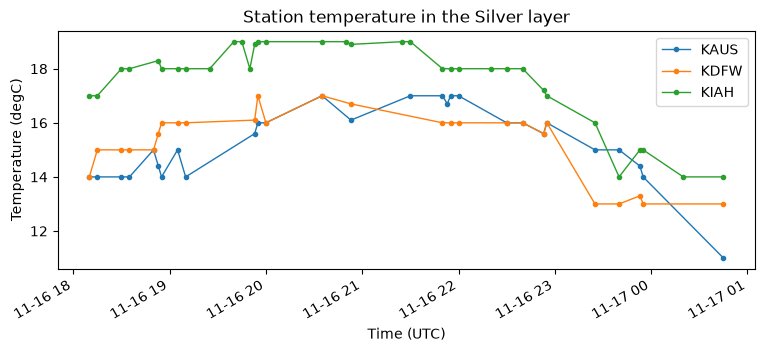

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for icao, group in obs.sort_values("timestamp_utc").groupby("icao", observed=True):
    ax.plot(group["timestamp_utc"], group["temperature_c"], marker=".", linewidth=1, label=icao)
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Temperature (degC)")
ax.set_title("Station temperature in the Silver layer")
ax.legend()
fig.autofmt_xdate()
plt.show()

## 5. Weather alerts (F3)

Categories, UTC times and the cleaned description text with its tokens.

In [9]:
print(alerts["message_type"].value_counts().to_dict())
print(alerts["severity"].value_counts().to_dict())
print("Without geometry:", int((~alerts["has_geometry"]).sum()), "of", len(alerts))
alerts["event"].value_counts().head(8)

{'Alert': 85, 'Update': 65, 'Cancel': 19}
{'Moderate': 79, 'Minor': 58, 'Severe': 32}
Without geometry: 77 of 169


event
Dense Fog Advisory             31
Flood Warning                  31
Flood Advisory                 26
Special Weather Statement      26
Wind Advisory                  16
Severe Thunderstorm Warning    11
Coastal Flood Advisory         10
Rip Current Statement           9
Name: count, dtype: int64

In [10]:
sample = alerts.sort_values("sent_utc").iloc[-1]
print("event:      ", sample["event"], "|", sample["severity"], "|", sample["message_type"])
print("sent_utc:   ", sample["sent_utc"])
print("ugc_codes:  ", list(sample["ugc_codes"])[:6])
print("description:", sample["description"][:200].replace("\n", " "))
print("clean:      ", sample["description_clean"][:200])
print("tokens:     ", list(sample["description_tokens"])[:15])

event:       Rip Current Statement | Moderate | Update
sent_utc:    2026-11-16 22:49:00+00:00
ugc_codes:   ['TXZ345', 'TXZ442', 'TXZ443', 'TXZ447']
description: * WHAT...For the Coastal Flood Advisory, minor coastal flooding. For the High Rip Current Risk, dangerous rip currents.  * WHERE...Aransas Islands, Kleberg Islands, Nueces Islands and Calhoun Islands 
clean:       what for the coastal flood advisory minor coastal flooding for the high rip current risk dangerous rip currents where aransas islands kleberg islands nueces islands and calhoun islands counties when f
tokens:      ['coastal', 'flood', 'advisory', 'minor', 'coastal', 'flooding', 'high', 'rip', 'current', 'risk', 'dangerous', 'rip', 'currents', 'aransas', 'islands']


In [11]:
alerts["description_tokens"].explode().value_counts().head(15)

description_tokens
flood       224
flooding    199
feet        196
cst         165
minor       150
stage       138
expected    135
river       112
impacts     102
rip         100
coastal      92
pm           91
texas        88
near         86
high         85
Name: count, dtype: int64

## 6. Daily summaries (F2)

Values are numbers (they arrive as text in the source), trace precipitation keeps 0.0 with `is_trace`,
and the outlier flags mark values without removing them.

In [12]:
print("Days per station:", daily["icao"].value_counts().to_dict())
print("Date range:", daily["date"].min().date(), "to", daily["date"].max().date())
print("Trace days:", int(daily["is_trace"].sum()), "| null PRCP:", int(daily["prcp_mm"].isna().sum()))
print("Flags:", daily[["tmax_outlier", "tmin_outlier", "prcp_outlier", "tmin_above_tmax"]].sum().to_dict())
daily.sort_values(["icao", "date"]).groupby("icao", observed=True).tail(3)[
    ["icao", "date", "tmax_c", "tmin_c", "prcp_mm", "is_trace", "tmax_s_flag", "bronze_file"]]

Days per station: {'KAUS': 389, 'KDFW': 389, 'KIAH': 388}
Date range: 2025-01-01 to 2026-11-10
Trace days: 142 | null PRCP: 2
Flags: {'tmax_outlier': 37, 'tmin_outlier': 1, 'prcp_outlier': 18, 'tmin_above_tmax': 0}


,icao,date,tmax_c,tmin_c,prcp_mm,is_trace,tmax_s_flag,bronze_file
70,KAUS,2026-11-08,17.2,15.0,10.4,False,1,ghcn_daily_20261117_000000.json
36,KAUS,2026-11-09,17.8,15.0,1.5,False,1,ghcn_daily_20261117_000000.json
19,KAUS,2026-11-10,20.6,13.3,2.3,False,1,ghcn_daily_20261117_000000.json
22,KDFW,2026-11-08,21.1,13.3,0.0,True,1,ghcn_daily_20261117_000000.json
23,KDFW,2026-11-09,22.2,12.8,0.0,False,1,ghcn_daily_20261117_000000.json
24,KDFW,2026-11-10,25.6,15.0,0.5,False,1,ghcn_daily_20261117_000000.json
44,KIAH,2026-11-07,27.2,17.2,0.0,False,1,ghcn_daily_20261117_000000.json
45,KIAH,2026-11-08,18.9,14.4,0.0,True,1,ghcn_daily_20261117_000000.json
46,KIAH,2026-11-09,18.9,13.3,0.3,False,1,ghcn_daily_20261117_000000.json


## 7. Storm events (F1)

Local standard time converted to UTC, damage text converted to USD (blank stays null) and magnitude
converted to SI units by event type.

In [13]:
print("Rows:", len(storms), "| zone rows without coordinates:", int(storms["begin_lat"].isna().sum()))
print("Damage unknown (null):", f"{storms['damage_property_usd'].isna().mean() * 100:.1f}%")
storms.groupby("event_type", observed=True).agg(
    events=("event_id", "size"), damage_usd=("damage_property_usd", "sum"),
    damage_outliers=("damage_outlier", "sum")).sort_values("events", ascending=False).head(8)

Rows: 5641 | zone rows without coordinates: 2069
Damage unknown (null): 15.7%


,events,damage_usd,damage_outliers
event_type,,,
Hail,1453,5457750.0,38
Thunderstorm Wind,1205,30255700.0,14
Flash Flood,624,427962000.0,5
Drought,611,0.0,0
High Wind,448,80000.0,0
Heat,347,0.0,0
Cold/Wind Chill,188,0.0,0
Tornado,143,16062500.0,0


In [14]:
storms[["event_id", "event_type", "cz_name", "begin_local", "cz_timezone", "begin_utc", "magnitude",
        "magnitude_unit", "damage_property_usd"]].sort_values("damage_property_usd", ascending=False).head(5)

,event_id,event_type,cz_name,begin_local,cz_timezone,begin_utc,magnitude,magnitude_unit,damage_property_usd
4965,1287369,Flash Flood,KERR,04-JUL-25 03:00:00,CST-6,2025-07-04 09:00:00+00:00,NaN,NaN,200000000.0
4345,1249939,Flash Flood,CAMERON,27-MAR-25 19:00:00,CST-6,2025-03-28 01:00:00+00:00,NaN,NaN,105000000.0
4344,1246573,Flash Flood,HIDALGO,27-MAR-25 14:30:00,CST-6,2025-03-27 20:30:00+00:00,NaN,NaN,52000000.0
4943,1288021,Flash Flood,WILLIAMSON,05-JUL-25 08:00:00,CST-6,2025-07-05 14:00:00+00:00,NaN,NaN,25000000.0
3747,1272324,Flash Flood,BEXAR,12-JUN-25 03:15:00,CST-6,2025-06-12 09:15:00+00:00,NaN,NaN,23000000.0
